# Bike-Sharing Demand Prediction

### Dataset: Capital Bikeshare (2011-2012)
### Files: day.csv and hour.csv

## Dataset Reading and Understanding

In [2]:
import pandas as pd, numpy as np, os, json
day_path='bike+sharing+dataset (1) (1)/day.csv'
hour_path='bike+sharing+dataset (1) (1)/hour.csv'
day=pd.read_csv(day_path)
hour=pd.read_csv(hour_path)
for name,df in [('day',day),('hour',hour)]:
    print('\n',name, df.shape)
    print(df.head(5).to_string())
    print('\ndtypes\n',df.dtypes)
    print('\nmissing',df.isna().sum().to_dict())
    print('duplicates',df.duplicated().sum())
    print('\nsummary cnt',df['cnt'].describe().to_dict())
    print('date range',df.dteday.min(),df.dteday.max())



 day (731, 16)
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  weathersit      temp     atemp       hum  windspeed  casual  registered   cnt
0        1  2011-01-01       1   0     1        0        6           0           2  0.344167  0.363625  0.805833   0.160446     331         654   985
1        2  2011-01-02       1   0     1        0        0           0           2  0.363478  0.353739  0.696087   0.248539     131         670   801
2        3  2011-01-03       1   0     1        0        1           1           1  0.196364  0.189405  0.437273   0.248309     120        1229  1349
3        4  2011-01-04       1   0     1        0        2           1           1  0.200000  0.212122  0.590435   0.160296     108        1454  1562
4        5  2011-01-05       1   0     1        0        3           1           1  0.226957  0.229270  0.436957   0.186900      82        1518  1600

dtypes
 instant         int64
dteday            str
season          int64
yr       

## IMPORT LIBRARIES AND CONFIGURATION

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor


In [5]:
RANDOM_STATE = 42

In [9]:
DATA_MODE = "hour"

DATA_PATHS = {
    "hour": "bike+sharing+dataset (1) (1)/hour.csv",
    "day": "bike+sharing+dataset (1) (1)/day.csv"
}

In [10]:
TARGET = "cnt"
PLOT_STYLE = "whitegrid"
sns.set_theme(style=PLOT_STYLE)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## Dataset Reading and Preprocessing

In [13]:
file_path = DATA_PATHS[DATA_MODE]
df = pd.read_csv(file_path)

print(f"BIKE-SHARING DATA ANALYSIS: {DATA_MODE.upper()} DATASET")
print(f"File loaded: {file_path}")
print("First 10 records:")
print(df.head(10))

BIKE-SHARING DATA ANALYSIS: HOUR DATASET
File loaded: bike+sharing+dataset (1) (1)/hour.csv
First 10 records:
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp   atemp   hum  windspeed  casual  registered  \
0        1  2011-01-01       1   0     1   0        0        6           0           1  0.24  0.2879  0.81     0.0000       3          13   
1        2  2011-01-01       1   0     1   1        0        6           0           1  0.22  0.2727  0.80     0.0000       8          32   
2        3  2011-01-01       1   0     1   2        0        6           0           1  0.22  0.2727  0.80     0.0000       5          27   
3        4  2011-01-01       1   0     1   3        0        6           0           1  0.24  0.2879  0.75     0.0000       3          10   
4        5  2011-01-01       1   0     1   4        0        6           0           1  0.24  0.2879  0.75     0.0000       0           1   
5        6  2011-01-01       1   0     1   5

In [ ]:
# Convert date to datetime. This enables reliable date-based feature
df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")

## Basic Dataset Audit (Removal of Missing or duplicate rows)

In [16]:
print("\nShape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nNumerical summary:")
print(df.describe().T)


Shape (rows, columns): (17379, 17)

Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types:
instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Numerical summary:
              count                        mean                  min                  25%                  50%                  75%  \
instant     17379.0                      8690.0                  1.0               4345.5               

In [18]:
print("\nMissing values per column:")
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df)) * 100
missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent.round(2)
})
print(missing_report)


Missing values per column:
            missing_count  missing_percent
instant                 0              0.0
dteday                  0              0.0
season                  0              0.0
yr                      0              0.0
mnth                    0              0.0
hr                      0              0.0
holiday                 0              0.0
weekday                 0              0.0
workingday              0              0.0
weathersit              0              0.0
temp                    0              0.0
atemp                   0              0.0
hum                     0              0.0
windspeed               0              0.0
casual                  0              0.0
registered              0              0.0
cnt                     0              0.0


In [19]:
print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDuplicate dates:", df["dteday"].duplicated().sum())
if DATA_MODE == "hour":
    print("Note: repeated dates are expected in hourly data because each day "
          "contains multiple hourly observations.")

print("\nTarget distribution:")
print(df[TARGET].describe())

print("\nInference:")
print(f"- The dataset contains {len(df):,} observations and {df.shape[1]} columns.")
print("- Missingness, duplicate rows, data types and target ranges are checked "
      "before modelling.")
print("- The dataset covers two calendar years (2011 and 2012).")
print("- A repeated date in the hourly dataset is not a duplicate record; "
      "the hour is part of the observation's identity.")


Exact duplicate rows: 0

Duplicate dates: 16648
Note: repeated dates are expected in hourly data because each day contains multiple hourly observations.

Target distribution:
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

Inference:
- The dataset contains 17,379 observations and 17 columns.
- Missingness, duplicate rows, data types and target ranges are checked before modelling.
- The dataset covers two calendar years (2011 and 2012).
- A repeated date in the hourly dataset is not a duplicate record; the hour is part of the observation's identity.


## COLUMN REVIEW AND REMOVAL OF UNREQUIRED / LEAKAGE COLUMNS

In [20]:
# instant is only a row identifier; it has no stable predictive meaning.
# casual and registered sum exactly to cnt. Including either as predictors
# would leak direct information about the target.
columns_to_drop = ["instant", "casual", "registered"]

In [21]:
existing_drop = [c for c in columns_to_drop if c in df.columns]
df = df.drop(columns=existing_drop)

In [22]:
print("\nColumns removed:", existing_drop)
print("Columns retained for analysis:", df.columns.tolist())

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")


Columns removed: ['instant', 'casual', 'registered']
Columns retained for analysis: ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']


In [23]:
# Remove rows with invalid dates or missing target.
df = df.dropna(subset=["dteday", TARGET]).copy()
df = df.sort_values(["dteday"] + (["hr"] if "hr" in df.columns else []))
df = df.reset_index(drop=True)

In [24]:
print("\nInference:")
print("- instant is excluded because it is an arbitrary record number.")
print("- casual and registered are excluded because cnt = casual + registered.")
print("- dteday is used to derive useful time features, not passed as raw text.")


Inference:
- instant is excluded because it is an arbitrary record number.
- casual and registered are excluded because cnt = casual + registered.
- dteday is used to derive useful time features, not passed as raw text.


## Missing Value Handling (Not Required here as no missing value is found)

In [25]:
# This code implements:
#   missing_data < 5% missing: remove affected rows.
#   missing_data >= 5% missing: impute numerical fields with median.
# For categorical columns, use the most frequent category.
missing_pct = df.isna().mean() * 100
low_missing_cols = missing_pct[(missing_pct > 0) & (missing_pct < 5)].index.tolist()
high_missing_cols = missing_pct[missing_pct >= 5].index.tolist()

if low_missing_cols:
    before = len(df)
    df = df.dropna(subset=low_missing_cols)
    print(f"Removed {before - len(df)} rows due to <5% missingness in "
          f"{low_missing_cols}.")

In [27]:
numeric_for_impute = df.select_dtypes(include=np.number).columns.tolist()
categorical_for_impute = df.select_dtypes(exclude=np.number).columns.tolist()

for col in high_missing_cols:
    if col in numeric_for_impute:
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("\nMissing values after handling:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nInference:")
if df.isna().sum().sum() == 0:
    print("- No missing values remain in the working dataset.")
else:
    print("- Some missing values remain; inspect the report before proceeding.")
print("- Median imputation is robust to skew and extreme numerical observations.")
print("- The sklearn pipeline independently imputes features using training-fold "
      "statistics only.")


Missing values after handling:
Series([], dtype: int64)

Inference:
- No missing values remain in the working dataset.
- Median imputation is robust to skew and extreme numerical observations.
- The sklearn pipeline independently imputes features using training-fold statistics only.


## Categorical and Numerical feature identification

In [30]:
categorical_candidates = [
    "season", "yr", "mnth", "hr", "holiday",
    "weekday", "workingday", "weathersit"
]
categorical_columns = [c for c in categorical_candidates if c in df.columns]

continuous_columns = [
    c for c in ["temp", "atemp", "hum", "windspeed"] if c in df.columns
]

print("\nCategorical columns:", categorical_columns)
print("Continuous columns:", continuous_columns)

print("\nCategory counts:")
for col in categorical_columns:
    print(df[col].value_counts(dropna=False).sort_index())

print("\nInference:")
print("- Numeric storage does not automatically make a variable continuous.")
print("- One-hot encoding is used for nominal categories such as season and "
      "weather situation.")
print("- Continuous weather measurements are scaled separately.")


Categorical columns: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit']
Continuous columns: ['temp', 'atemp', 'hum', 'windspeed']

Category counts:
season
1    4242
2    4409
3    4496
4    4232
Name: count, dtype: int64
yr
0    8645
1    8734
Name: count, dtype: int64
mnth
1     1429
2     1341
3     1473
4     1437
5     1488
6     1440
7     1488
8     1475
9     1437
10    1451
11    1437
12    1483
Name: count, dtype: int64
hr
0     726
1     724
2     715
3     697
4     697
5     717
6     725
7     727
8     727
9     727
10    727
11    727
12    728
13    729
14    729
15    729
16    730
17    730
18    728
19    728
20    728
21    728
22    728
23    728
Name: count, dtype: int64
holiday
0    16879
1      500
Name: count, dtype: int64
weekday
0    2502
1    2479
2    2453
3    2475
4    2471
5    2487
6    2512
Name: count, dtype: int64
workingday
0     5514
1    11865
Name: count, dtype: int64
weathersit
1    11413
2     4544
3     1419
4   

## Outlier Detection

In [31]:
outlier_summary = []

for col in continuous_columns + [TARGET]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "feature": col,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(count),
        "outlier_percent": 100 * count / len(df)
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.round(3).to_string(index=False))

  feature  lower_fence  upper_fence  outlier_count  outlier_percent
     temp       -0.140        1.140              0            0.000
    atemp       -0.099        1.053              0            0.000
      hum        0.030        1.230             22            0.127
windspeed       -0.119        0.478            342            1.968
      cnt     -321.500      642.500            505            2.906


In [33]:
print("\nInference:")
print("- IQR fences identify observations that deserve investigation; they do "
      "not prove that those observations are errors.")
print("- High rental counts may represent rush hours, seasonal peaks or events.")
print("- Low counts may represent severe weather or holidays.")
print("- Keep plausible observations. Correct or remove only confirmed data "
      "errors. This preserves the operational extremes the model must learn.")


Inference:
- IQR fences identify observations that deserve investigation; they do not prove that those observations are errors.
- High rental counts may represent rush hours, seasonal peaks or events.
- Low counts may represent severe weather or holidays.
- Keep plausible observations. Correct or remove only confirmed data errors. This preserves the operational extremes the model must learn.


## Univariate EDA

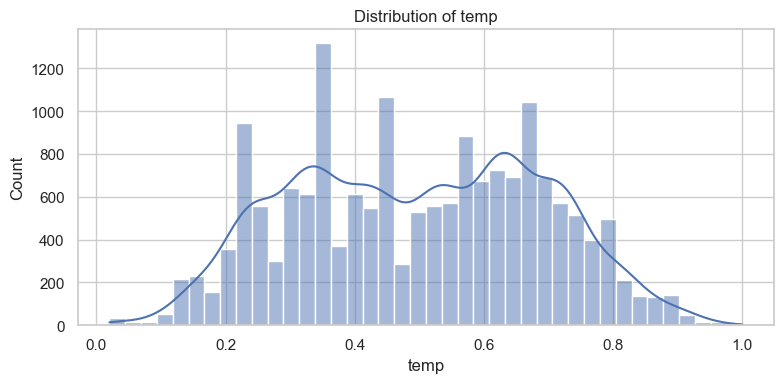

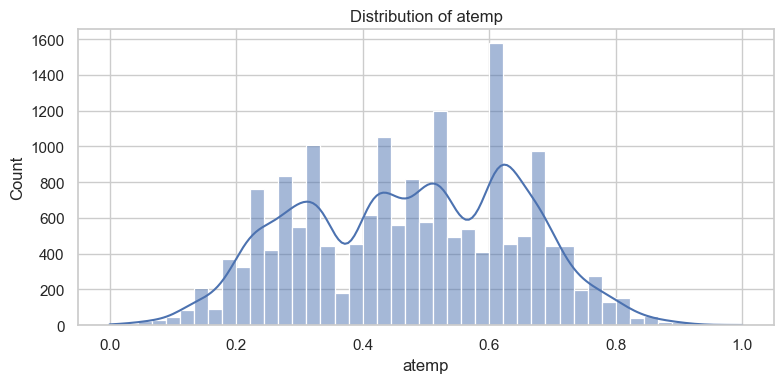

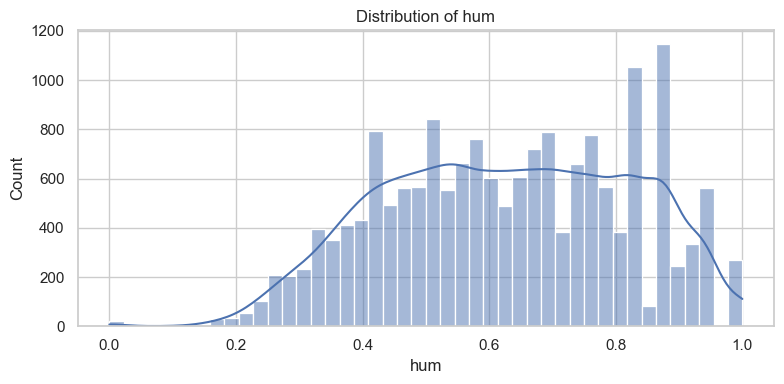

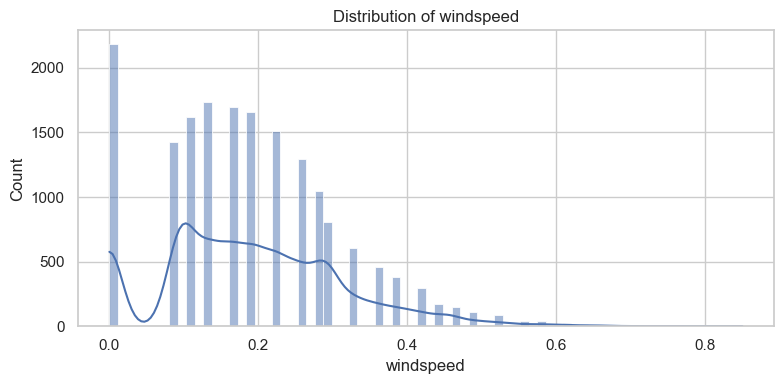

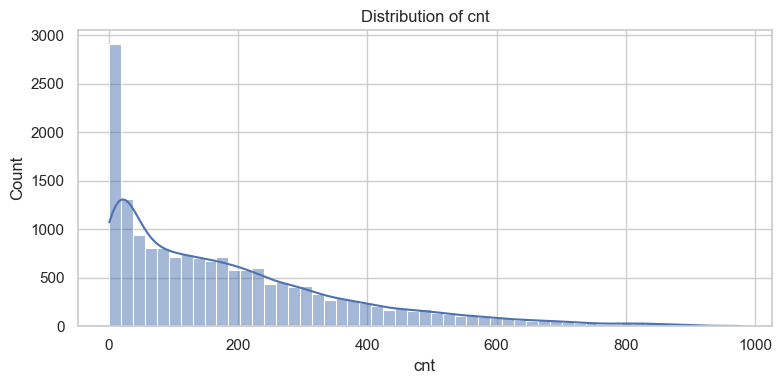

In [34]:
univariate_columns = continuous_columns + [TARGET]

for col in univariate_columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

In [36]:
skew_value = df[col].skew()
print(f"Inference - {col}: skewness = {skew_value:.3f}.")
if skew_value > 0.5:
    print(f"  {col} is positively skewed; a longer right tail is present.")
elif skew_value < -0.5:
    print(f"  {col} is negatively skewed; a longer left tail is present.")
else:
    print(f"  {col} is approximately symmetric (based on the skewness rule).")

Inference - cnt: skewness = 1.277.
  cnt is positively skewed; a longer right tail is present.


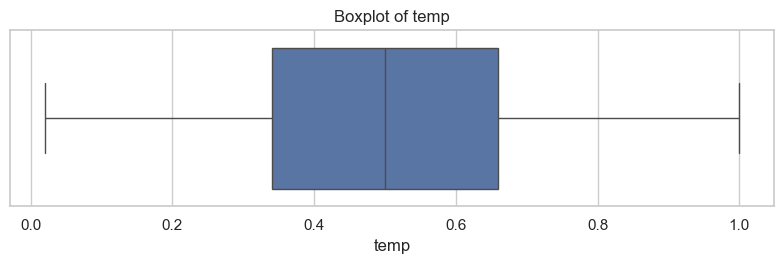

Inference - temp: the boxplot displays the median, IQR and potential extreme observations. Verify extremes before treating them as errors.


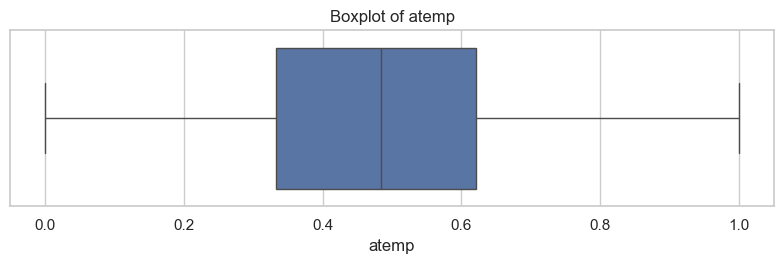

Inference - atemp: the boxplot displays the median, IQR and potential extreme observations. Verify extremes before treating them as errors.


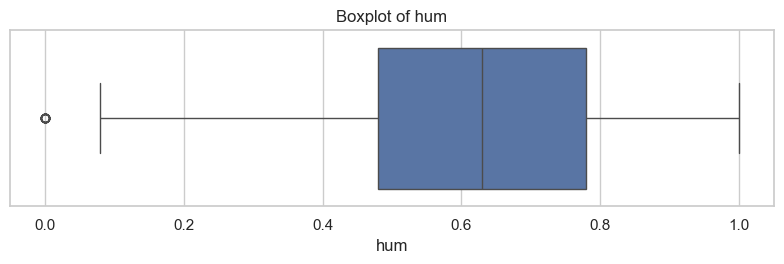

Inference - hum: the boxplot displays the median, IQR and potential extreme observations. Verify extremes before treating them as errors.


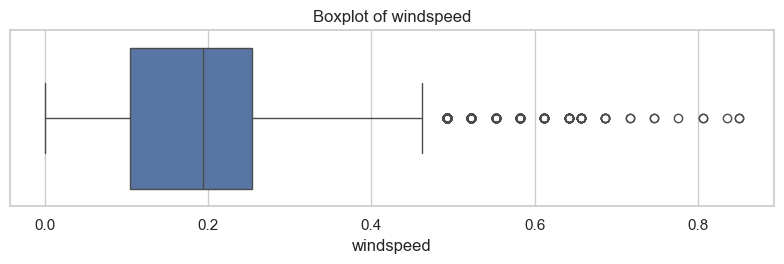

Inference - windspeed: the boxplot displays the median, IQR and potential extreme observations. Verify extremes before treating them as errors.


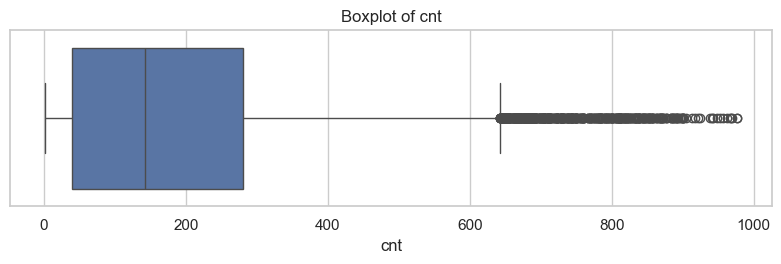

Inference - cnt: the boxplot displays the median, IQR and potential extreme observations. Verify extremes before treating them as errors.


In [37]:
for col in univariate_columns:
    fig, ax = plt.subplots(figsize=(8, 2.8))
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()
    print(f"Inference - {col}: the boxplot displays the median, IQR and "
          "potential extreme observations. Verify extremes before treating "
          "them as errors.")

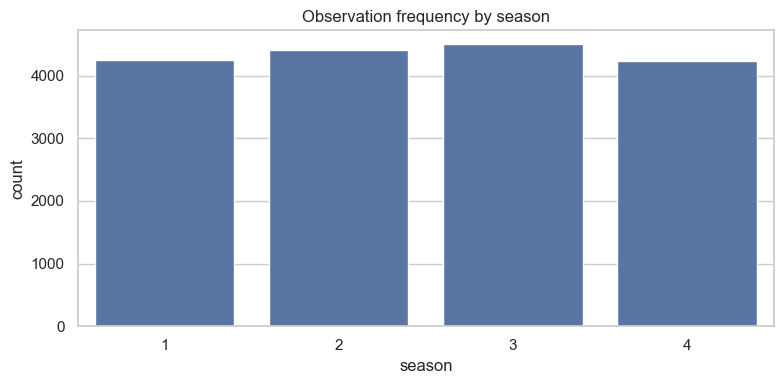

Inference - season: this chart checks whether observations are balanced across categories; imbalance can affect comparisons.


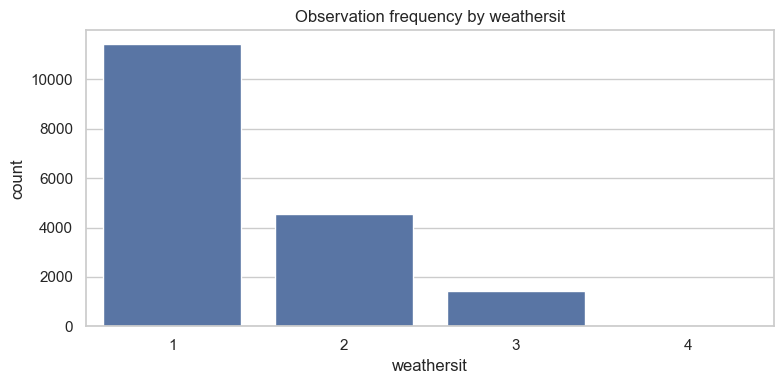

Inference - weathersit: this chart checks whether observations are balanced across categories; imbalance can affect comparisons.


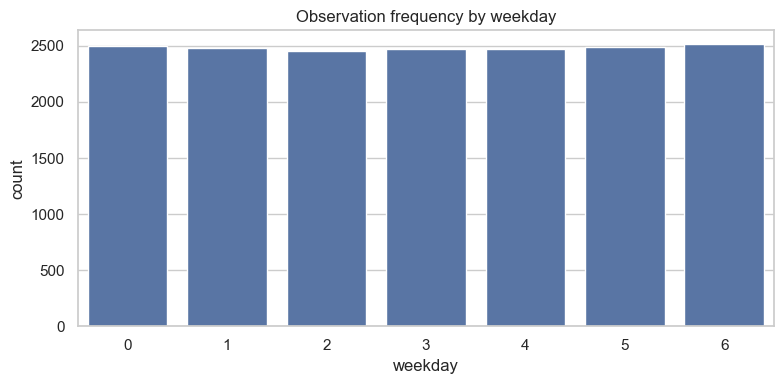

Inference - weekday: this chart checks whether observations are balanced across categories; imbalance can affect comparisons.


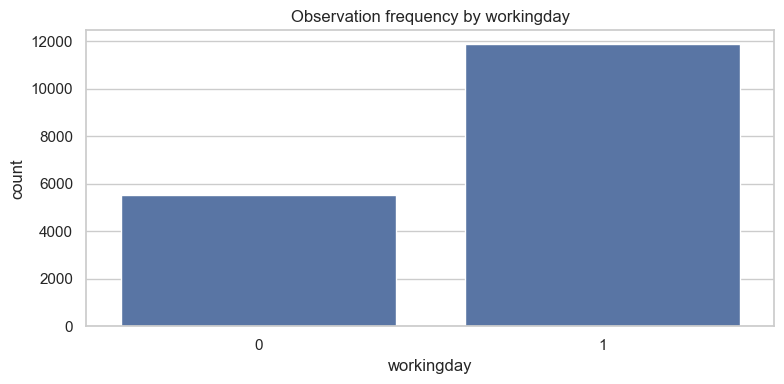

Inference - workingday: this chart checks whether observations are balanced across categories; imbalance can affect comparisons.


In [38]:
for col in [c for c in ["season", "weathersit", "weekday", "workingday"] if c in df.columns]:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Observation frequency by {col}")
    plt.tight_layout()
    plt.show()
    print(f"Inference - {col}: this chart checks whether observations are "
          "balanced across categories; imbalance can affect comparisons.")

## Bivariate EDA

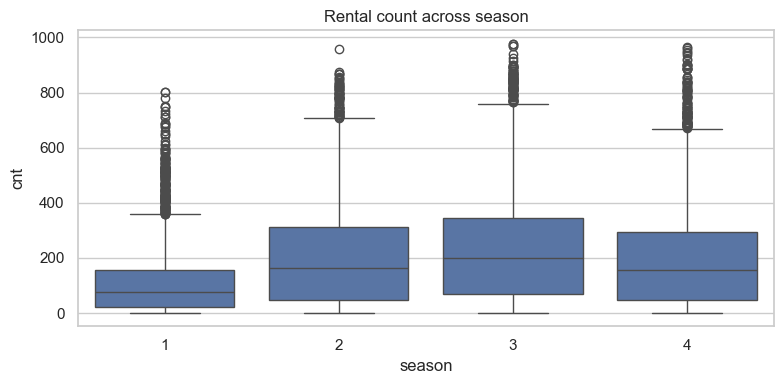

\nInference - rental demand grouped by season:
          mean  median  count
season                       
1       111.11    76.0   4242
2       208.34   165.0   4409
3       236.02   199.0   4496
4       198.87   155.5   4232
  Highest average demand category: 3.


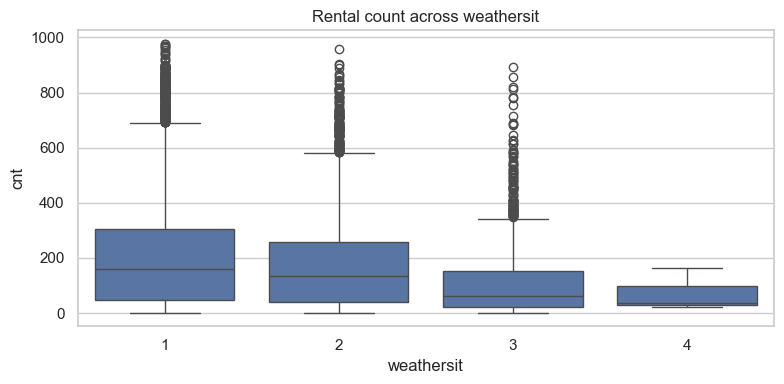

\nInference - rental demand grouped by weathersit:
              mean  median  count
weathersit                       
1           204.87   159.0  11413
2           175.17   133.0   4544
3           111.58    63.0   1419
4            74.33    36.0      3
  Highest average demand category: 1.


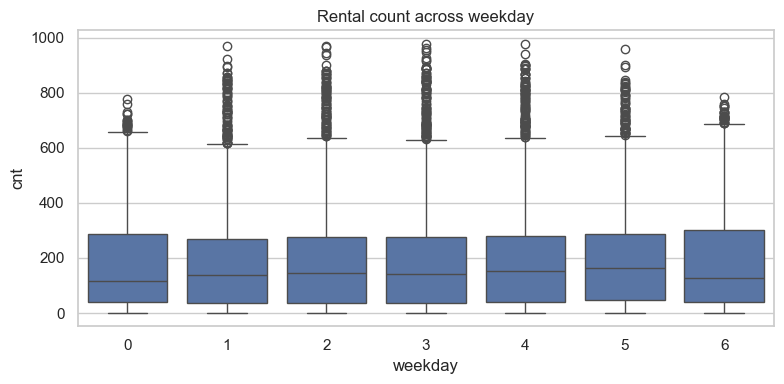

\nInference - rental demand grouped by weekday:
           mean  median  count
weekday                       
0        177.47   116.0   2502
1        183.74   139.0   2479
2        191.24   147.0   2453
3        191.13   143.0   2475
4        196.44   154.0   2471
5        196.14   165.0   2487
6        190.21   129.0   2512
  Highest average demand category: 4.


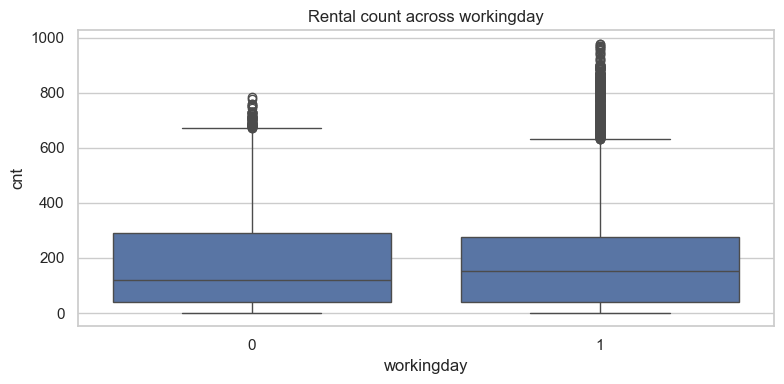

\nInference - rental demand grouped by workingday:
              mean  median  count
workingday                       
0           181.41   119.0   5514
1           193.21   151.0  11865
  Highest average demand category: 1.


In [41]:
for col in [c for c in ["season", "weathersit", "weekday", "workingday"] if c in df.columns]:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"Rental count across {col}")
    plt.tight_layout()
    plt.show()

    grouped = df.groupby(col)[TARGET].agg(["mean", "median", "count"])
    print(f"\\nInference - rental demand grouped by {col}:")
    print(grouped.round(2))
    print(f"  Highest average demand category: {grouped['mean'].idxmax()}.")

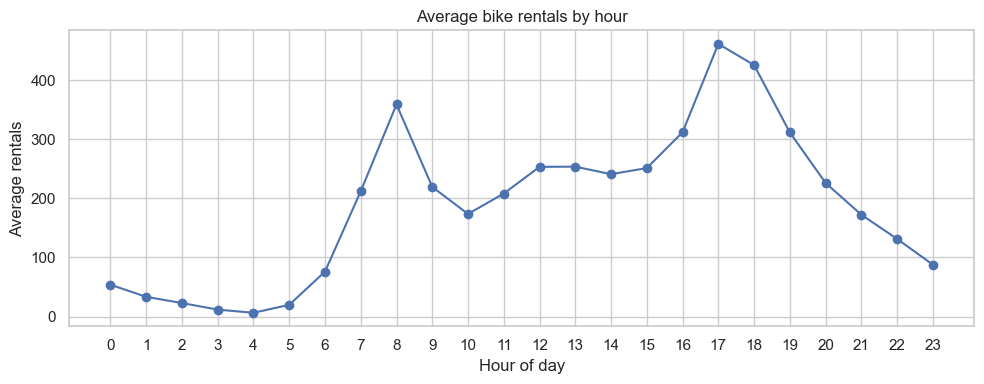

In [42]:
if "hr" in df.columns:
    hourly_profile = df.groupby("hr")[TARGET].mean()
    fig, ax = plt.subplots(figsize=(10, 4))
    hourly_profile.plot(marker="o", ax=ax)
    ax.set_title("Average bike rentals by hour")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Average rentals")
    ax.set_xticks(range(0, 24))
    plt.tight_layout()
    plt.show()

In [44]:
    print("\nInference - hourly profile:")
    print(f"  Peak average rental hour: {hourly_profile.idxmax()}:00 "
          f"({hourly_profile.max():.1f} rentals).")
    print(f"  Lowest average rental hour: {hourly_profile.idxmin()}:00 "
          f"({hourly_profile.min():.1f} rentals).")
    print("  Strong hourly peaks indicate that fleet availability should be "
          "managed dynamically rather than uniformly.")


Inference - hourly profile:
  Peak average rental hour: 17:00 (461.5 rentals).
  Lowest average rental hour: 4:00 (6.4 rentals).
  Strong hourly peaks indicate that fleet availability should be managed dynamically rather than uniformly.


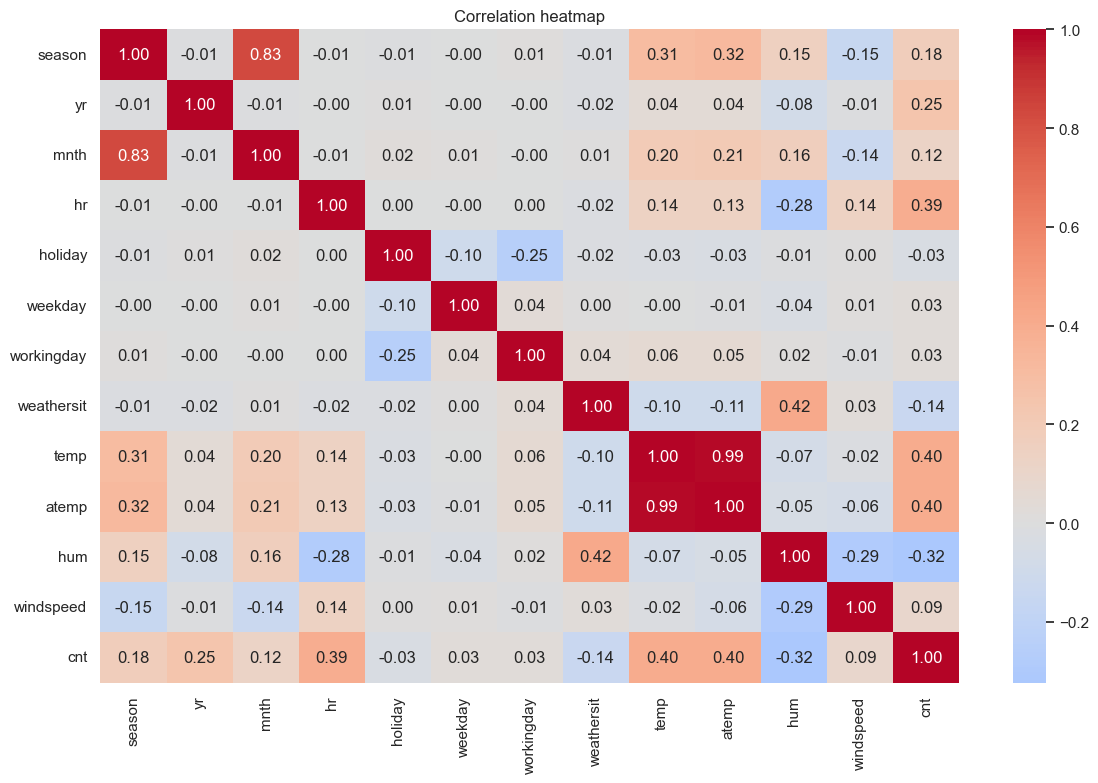

\nCorrelation with target:
cnt           1.000
temp          0.405
atemp         0.401
hr            0.394
yr            0.250
season        0.178
mnth          0.121
windspeed     0.093
workingday    0.030
weekday       0.027
holiday      -0.031
weathersit   -0.142
hum          -0.323
Name: cnt, dtype: float64

Inference:
- Correlation describes pairwise linear association, not causation.
- Strongly correlated predictors (for example temp and atemp) may carry overlapping information.
- The heatmap helps identify relationships, but feature importance and holdout performance are needed for model-level conclusions.


In [46]:
numeric_for_corr = df.select_dtypes(include=np.number).columns.tolist()
corr_matrix = df[numeric_for_corr].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print("\\nCorrelation with target:")
print(corr_matrix[TARGET].sort_values(ascending=False).round(3))
print("\nInference:")
print("- Correlation describes pairwise linear association, not causation.")
print("- Strongly correlated predictors (for example temp and atemp) may carry "
      "overlapping information.")
print("- The heatmap helps identify relationships, but feature importance and "
      "holdout performance are needed for model-level conclusions.")

## Feature Engineering

In [ ]:
df["year_num"] = df["dteday"].dt.year
df["day_of_year"] = df["dteday"].dt.dayofyear
df["day_of_month"] = df["dteday"].dt.day
df["days_since_start"] = (df["dteday"] - df["dteday"].min()).dt.days

# Cyclical encoding respects wrap-around:
# 23:00 is close to 00:00; December is close to January.
if "hr" in df.columns:
    df["hour_sin"] = np.sin(2 * np.pi * df["hr"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hr"] / 24)

df["month_sin"] = np.sin(2 * np.pi * (df["dteday"].dt.month - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["dteday"].dt.month - 1) / 12)
df["dayofweek_sin"] = np.sin(2 * np.pi * df["dteday"].dt.dayofweek / 7)
df["dayofweek_cos"] = np.cos(2 * np.pi * df["dteday"].dt.dayofweek / 7)

# Use cyclical forms for hour/month/day-of-week; remove their raw integer
# versions to avoid treating them as linear magnitudes.
for col in ["hr", "mnth", "weekday"]:
    if col in df.columns:
        df = df.drop(columns=col)

# Remove raw date after deriving numeric calendar features.
df = df.drop(columns=["dteday"])

# The target must not appear among predictors.
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(float)

# Define categorical predictors after feature engineering.
categorical_features = [
    c for c in ["season", "yr", "holiday", "workingday", "weathersit"]
    if c in X.columns
]

In [53]:
# year_num is a calendar trend feature; days_since_start is also numeric.
# The remaining numeric predictors are scaled using MinMaxScaler.
numeric_features = [c for c in X.columns if c not in categorical_features]

print("\nFinal feature columns:")
print(X.columns.tolist())
print("\nCategorical model features:", categorical_features)
print("Numerical model features:", numeric_features)
print("\nMissing values in X:", int(X.isna().sum().sum()))
print("Missing values in y:", int(y.isna().sum()))

print("\nInference:")
print("- Cyclical encoding represents repeating time patterns without an "
      "artificial jump between the final and first period.")
print("- Min-Max scaling maps numeric features to a comparable range.")
print("- Scaling and imputation are fitted inside each training fold, not on "
      "the complete dataset.")


Final feature columns:
['season', 'yr', 'holiday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'year_num', 'day_of_year', 'day_of_month', 'days_since_start', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dayofweek_sin', 'dayofweek_cos']

Categorical model features: ['season', 'yr', 'holiday', 'workingday', 'weathersit']
Numerical model features: ['temp', 'atemp', 'hum', 'windspeed', 'year_num', 'day_of_year', 'day_of_month', 'days_since_start', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dayofweek_sin', 'dayofweek_cos']

Missing values in X: 0
Missing values in y: 0

Inference:
- Cyclical encoding represents repeating time patterns without an artificial jump between the final and first period.
- Min-Max scaling maps numeric features to a comparable range.
- Scaling and imputation are fitted inside each training fold, not on the complete dataset.


## Train Test Split

In [54]:
# For demand forecasting, a chronological split is more realistic than a
# random split: train on earlier dates and test on later, unseen dates.
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Train fraction:", round(len(X_train) / len(X), 3))
print("Test fraction:", round(len(X_test) / len(X), 3))

print("\nInference:")
print("- The model learns from the first 80% of the timeline and is evaluated "
      "on the final 20%.")
print("- This is a stronger forecasting simulation than random splitting, "
      "which can mix future and past observations.")



Training observations: 13903
Testing observations: 3476
Train fraction: 0.8
Test fraction: 0.2

Inference:
- The model learns from the first 80% of the timeline and is evaluated on the final 20%.
- This is a stronger forecasting simulation than random splitting, which can mix future and past observations.


## Preprocessing and Regression model

In [56]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Categorical: most-frequent imputation + one-hot encoding.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

# 5-fold time-series CV preserves chronological ordering within folds.
# cross_val_score returns negative MAE because sklearn maximizes scores.
tscv = TimeSeriesSplit(n_splits=5)

cv_results = []
for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    fold_scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=None
    )

    cv_mae = -fold_scores
    cv_results.append({
        "Model": model_name,
        "CV_MAE_mean": cv_mae.mean(),
        "CV_MAE_std": cv_mae.std()
    })

cv_table = pd.DataFrame(cv_results).sort_values("CV_MAE_mean")
print("5-FOLD TIME-SERIES CROSS-VALIDATION")
print(cv_table.round(3).to_string(index=False))

best_model_name = cv_table.iloc[0]["Model"]
print(f"\nBest model based on CV MAE: {best_model_name}")
print("Inference: lower cross-validation MAE indicates lower average absolute "
      "prediction error across the chronological validation folds.")


5-FOLD TIME-SERIES CROSS-VALIDATION
            Model  CV_MAE_mean  CV_MAE_std
      Extra Trees       49.349      13.870
    Random Forest       50.214      11.787
 Ridge Regression       98.215      20.206
Linear Regression      100.892      19.858

Best model based on CV MAE: Extra Trees
Inference: lower cross-validation MAE indicates lower average absolute prediction error across the chronological validation folds.


In [57]:
best_estimator = models[best_model_name]
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_estimator)
])

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

# Rental counts cannot be negative. Keep raw predictions for metric calculation;
# provide a non-negative operational prediction separately.
y_pred_operational = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# MAPE is unstable when actual demand is zero; this dataset's target is positive,
# but epsilon still makes the calculation robust.
mape = np.mean(
    np.abs((y_test.to_numpy() - y_pred) /
           np.maximum(np.abs(y_test.to_numpy()), 1e-8))
) * 100

metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2", "MAPE (%)"],
    "Value": [mae, mse, rmse, r2, mape]
})

print("\n" + "=" * 75)
print("HOLDOUT TEST PERFORMANCE")
print("=" * 75)
print("Selected model:", best_model_name)
print(metrics.round(3).to_string(index=False))

print("\nMetric interpretation:")
print(f"- MAE = {mae:.2f}: predictions are off by about {mae:.2f} bikes "
      "per observation on average.")
print(f"- RMSE = {rmse:.2f}: penalizes larger errors more strongly than MAE.")
print(f"- R2 = {r2:.3f}: fraction of target variance explained on the test set.")
print(f"- MAPE = {mape:.2f}%: average absolute percentage error; interpret "
      "carefully for very low demand.")

print("\nInference:")
print("- Use MAE as an intuitive operational error in number of bikes.")
print("- Compare CV MAE with test MAE. A much worse test result can indicate "
      "temporal drift or overfitting.")
print("- R2 alone is not sufficient: a model can have reasonable R2 while "
      "still making large errors during peak demand.")



HOLDOUT TEST PERFORMANCE
Selected model: Extra Trees
  Metric    Value
     MAE   45.893
     MSE 5033.953
    RMSE   70.950
      R2    0.896
MAPE (%)   34.904

Metric interpretation:
- MAE = 45.89: predictions are off by about 45.89 bikes per observation on average.
- RMSE = 70.95: penalizes larger errors more strongly than MAE.
- R2 = 0.896: fraction of target variance explained on the test set.
- MAPE = 34.90%: average absolute percentage error; interpret carefully for very low demand.

Inference:
- Use MAE as an intuitive operational error in number of bikes.
- Compare CV MAE with test MAE. A much worse test result can indicate temporal drift or overfitting.
- R2 alone is not sufficient: a model can have reasonable R2 while still making large errors during peak demand.


## Ablation Study and Inference

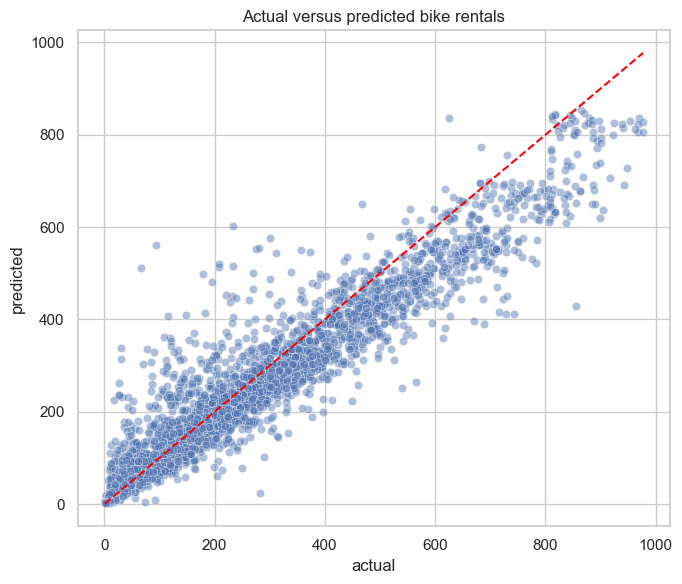

Inference: points close to the diagonal represent accurate predictions. Systematic deviations above or below the line indicate overprediction or underprediction.


In [61]:
results = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred,
    "predicted_nonnegative": y_pred_operational
}, index=y_test.index)

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=results, x="actual", y="predicted", alpha=0.45, ax=ax)
low = min(results["actual"].min(), results["predicted"].min())
high = max(results["actual"].max(), results["predicted"].max())
ax.plot([low, high], [low, high], linestyle="--", color="red")
ax.set_title("Actual versus predicted bike rentals")
plt.tight_layout()
plt.show()

print("Inference: points close to the diagonal represent accurate predictions. "
      "Systematic deviations above or below the line indicate overprediction "
      "or underprediction.")

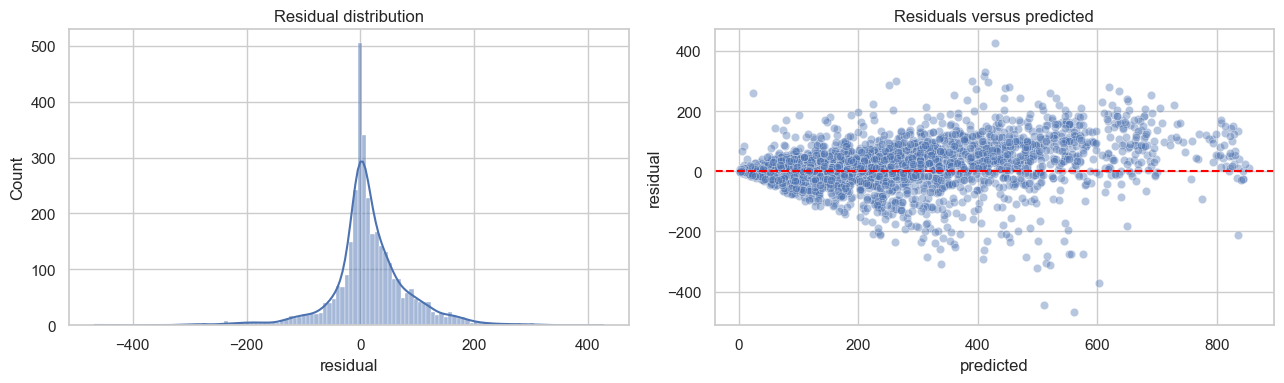

Inference: residuals should be centred around zero without a clear pattern. Curvature, changing spread or persistent bias can indicate nonlinearity, heteroscedasticity or missing explanatory variables.


In [62]:
results["residual"] = results["actual"] - results["predicted"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(results["residual"], kde=True, ax=axes[0])
axes[0].set_title("Residual distribution")
sns.scatterplot(x=results["predicted"], y=results["residual"], alpha=0.4,
                ax=axes[1])
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_title("Residuals versus predicted")
plt.tight_layout()
plt.show()

print("Inference: residuals should be centred around zero without a clear "
      "pattern. Curvature, changing spread or persistent bias can indicate "
      "nonlinearity, heteroscedasticity or missing explanatory variables.")

## Anomaly candidate detection

In [63]:
# Large residuals identify observations the model did not explain well.
# They are anomaly candidates, not confirmed real-world events.
residual_median = results["residual"].median()
residual_mad = np.median(np.abs(results["residual"] - residual_median))

if residual_mad > 0:
    robust_z = 0.6745 * (results["residual"] - residual_median) / residual_mad
    results["residual_robust_z"] = robust_z
    anomaly_candidates = results[np.abs(robust_z) > 3.5].copy()
else:
    results["residual_robust_z"] = 0.0
    anomaly_candidates = results.iloc[0:0].copy()

# Attach dates and hour for investigation.
date_info = df.loc[results.index, ["year_num"]].copy()
if DATA_MODE == "hour":
    # Re-read the original date/hour keys in their sorted order.
    original_keys = pd.read_csv(file_path)
    original_keys["dteday"] = pd.to_datetime(original_keys["dteday"])
    original_keys = original_keys.sort_values(
        ["dteday", "hr"] if "hr" in original_keys.columns else ["dteday"]
    ).reset_index(drop=True)
    date_info["date"] = original_keys.loc[results.index, "dteday"].to_numpy()
    date_info["hour"] = original_keys.loc[results.index, "hr"].to_numpy()
else:
    original_keys = pd.read_csv(file_path)
    original_keys["dteday"] = pd.to_datetime(original_keys["dteday"])
    original_keys = original_keys.sort_values("dteday").reset_index(drop=True)
    date_info["date"] = original_keys.loc[results.index, "dteday"].to_numpy()

anomaly_candidates = anomaly_candidates.join(date_info)
print("\\n" + "=" * 75)
print("UNUSUAL DEMAND / EVENT CANDIDATES IN TEST PERIOD")
print("=" * 75)
print(anomaly_candidates.head(30).to_string())
print(f"\\nNumber of candidate anomalies: {len(anomaly_candidates)}")
print("Inference:")
print("- A large positive residual means actual demand exceeded predicted demand.")
print("- A large negative residual means actual demand was below predicted demand.")
print("- Cross-check dates against weather records, public holidays, festivals, "
      "road closures, sporting events and major incidents.")
print("- Residual anomalies are investigation leads, not proof of an event.")


\n===========================================================================
UNUSUAL DEMAND / EVENT CANDIDATES IN TEST PERIOD
       actual   predicted  predicted_nonnegative    residual  residual_robust_z  year_num       date  hour
13908   868.0  707.329444             707.329444  160.670556           4.161892      2012 2012-08-07    17
13933   862.0  678.292222             678.292222  183.707778           4.788207      2012 2012-08-08    18
13957   811.0  672.281944             672.281944  138.718056           3.565068      2012 2012-08-09    18
13970   133.0  320.602778             320.602778 -187.602778          -5.306641      2012 2012-08-10     7
13971   119.0  359.736667             359.736667 -240.736667          -6.751196      2012 2012-08-10     8
13972   220.0  373.612222             373.612222 -153.612222          -4.382538      2012 2012-08-10     9
14004   512.0  361.025000             361.025000  150.975000           3.898298      2012 2012-08-11    17
14066   179.0  49

## Why Decision tree models performed well

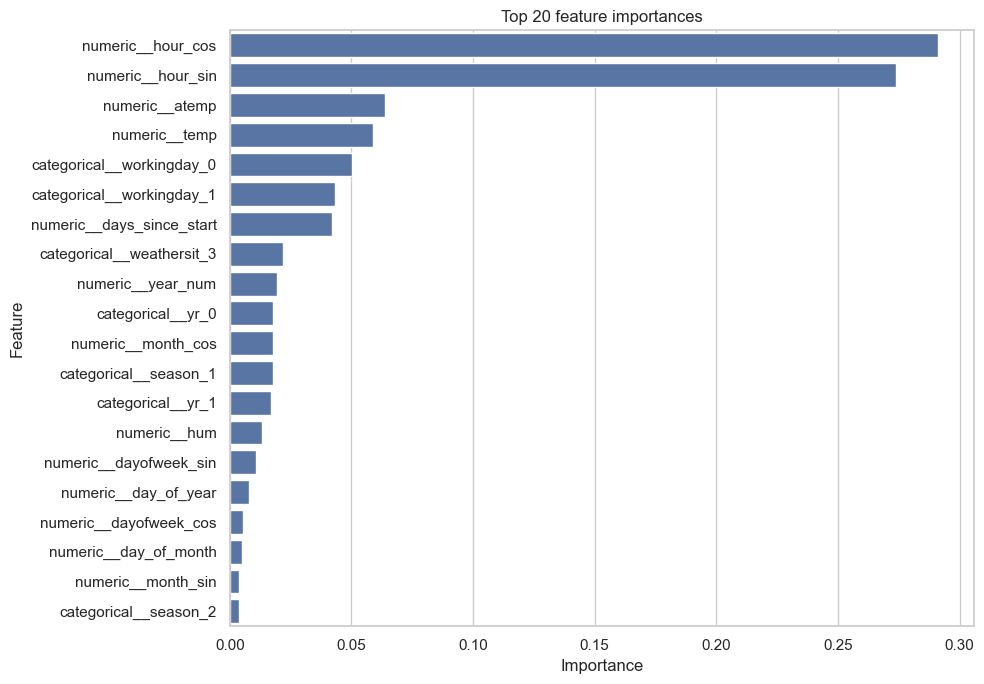


Top features:
numeric__hour_cos            0.291233
numeric__hour_sin            0.273932
numeric__atemp               0.063855
numeric__temp                0.058944
categorical__workingday_0    0.050190
categorical__workingday_1    0.043408
numeric__days_since_start    0.042118
categorical__weathersit_3    0.021926
numeric__year_num            0.019623
categorical__yr_0            0.017891
numeric__month_cos           0.017810
categorical__season_1        0.017582
categorical__yr_1            0.016910
numeric__hum                 0.013300
numeric__dayofweek_sin       0.010756
numeric__day_of_year         0.007934
numeric__dayofweek_cos       0.005522
numeric__day_of_month        0.004921
numeric__month_sin           0.003972
categorical__season_2        0.003767
dtype: float64
Inference: feature importance indicates which variables the fitted tree model relied on most. It does not establish causation.


In [64]:
if best_model_name in ["Random Forest", "Extra Trees"]:
    fitted_preprocessor = final_model.named_steps["preprocessor"]
    fitted_tree = final_model.named_steps["model"]

    try:
        feature_names = fitted_preprocessor.get_feature_names_out()
        importance = pd.Series(
            fitted_tree.feature_importances_,
            index=feature_names
        ).sort_values(ascending=False).head(20)

        plt.figure(figsize=(10, 7))
        sns.barplot(x=importance.values, y=importance.index)
        plt.title("Top 20 feature importances")
        plt.xlabel("Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

        print("\nTop features:")
        print(importance)
        print("Inference: feature importance indicates which variables the fitted "
              "tree model relied on most. It does not establish causation.")
    except Exception as exc:
        print("Could not extract feature importance:", exc)

## Boosting models

In [70]:
%pip install xgboost lightgbm

  Using cached xgboost-3.2.0-py3-none-macosx_12_0_arm64.whl.metadata (2.1 kB)
  Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl.metadata (18 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
Using cached xgboost-3.2.0-py3-none-macosx_12_0_arm64.whl (2.3 MB)
Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl (1.5 MB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lightgbm]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

boosting_models = {
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=6,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=-1,
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.1,
        random_state=RANDOM_STATE
    ),
}


tscv = TimeSeriesSplit(n_splits=5)

boosting_cv_results = []
for model_name, estimator in boosting_models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    fold_scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=None
    )

    cv_mae = -fold_scores
    boosting_cv_results.append({
        "Model": model_name,
        "CV_MAE_mean": cv_mae.mean(),
        "CV_MAE_std": cv_mae.std()
    })

boosting_cv_table = pd.DataFrame(boosting_cv_results).sort_values("CV_MAE_mean")

# ── Combine with earlier results ────────────────────────────────────
all_cv_table = pd.concat([cv_table, boosting_cv_table], ignore_index=True) \
                 .sort_values("CV_MAE_mean")

print("\n" + "=" * 75)
print("ALL MODELS — 5-FOLD TIME-SERIES CROSS-VALIDATION")
print("=" * 75)
print(all_cv_table.round(3).to_string(index=False))

best_overall_name = all_cv_table.iloc[0]["Model"]
print(f"\nBest model based on CV MAE: {best_overall_name}")
print("Inference: lower cross-validation MAE indicates lower average absolute "
      "prediction error across the chronological validation folds.")


ALL MODELS — 5-FOLD TIME-SERIES CROSS-VALIDATION
               Model  CV_MAE_mean  CV_MAE_std
HistGradientBoosting       47.804       8.638
            LightGBM       47.819       8.472
         Extra Trees       49.349      13.870
       Random Forest       50.214      11.787
             XGBoost       51.204       7.452
    Ridge Regression       98.215      20.206
   Linear Regression      100.892      19.858

Best model based on CV MAE: HistGradientBoosting
Inference: lower cross-validation MAE indicates lower average absolute prediction error across the chronological validation folds.


In [72]:
# ── Fit best boosting model on train, evaluate on holdout test set ──
best_boost_estimator = boosting_models[best_overall_name] \
    if best_overall_name in boosting_models else models[best_overall_name]

final_boost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_boost_estimator)
])

final_boost_pipeline.fit(X_train, y_train)
y_pred_boost = final_boost_pipeline.predict(X_test)
y_pred_boost_op = np.maximum(y_pred_boost, 0)

mae_b  = mean_absolute_error(y_test, y_pred_boost)
mse_b  = mean_squared_error(y_test, y_pred_boost)
rmse_b = np.sqrt(mse_b)
r2_b   = r2_score(y_test, y_pred_boost)
mape_b = np.mean(
    np.abs((y_test.to_numpy() - y_pred_boost) /
           np.maximum(np.abs(y_test.to_numpy()), 1e-8))
) * 100

boost_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2", "MAPE (%)"],
    "Value":  [mae_b, mse_b, rmse_b, r2_b, mape_b]
})

print("\n" + "=" * 75)
print("HOLDOUT TEST PERFORMANCE — BOOSTING MODELS")
print("=" * 75)
print(f"Selected model: {best_overall_name}")
print(boost_metrics.round(3).to_string(index=False))

print(f"\nMetric interpretation:")
print(f"- MAE = {mae_b:.2f}: predictions are off by about {mae_b:.2f} bikes "
      "per observation on average.")
print(f"- RMSE = {rmse_b:.2f}: penalizes larger errors more strongly than MAE.")
print(f"- R2 = {r2_b:.3f}: fraction of target variance explained on the test set.")
print(f"- MAPE = {mape_b:.2f}%: average absolute percentage error; interpret "
      "carefully for very low demand.")

print("\nInference:")
print("- Gradient boosting models (XGBoost, LightGBM, HistGradientBoosting) "
      "learn sequentially, correcting residual errors at each stage.")
print("- Compare CV MAE with test MAE. A much worse test result can indicate "
      "temporal drift or overfitting.")
print("- Boosting models typically outperform bagging (Random Forest, Extra Trees) "
      "and linear models on structured tabular data like bike-sharing demand.")


HOLDOUT TEST PERFORMANCE — BOOSTING MODELS
Selected model: HistGradientBoosting
  Metric    Value
     MAE   44.055
     MSE 4841.050
    RMSE   69.578
      R2    0.900
MAPE (%)   54.370

Metric interpretation:
- MAE = 44.06: predictions are off by about 44.06 bikes per observation on average.
- RMSE = 69.58: penalizes larger errors more strongly than MAE.
- R2 = 0.900: fraction of target variance explained on the test set.
- MAPE = 54.37%: average absolute percentage error; interpret carefully for very low demand.

Inference:
- Gradient boosting models (XGBoost, LightGBM, HistGradientBoosting) learn sequentially, correcting residual errors at each stage.
- Compare CV MAE with test MAE. A much worse test result can indicate temporal drift or overfitting.
- Boosting models typically outperform bagging (Random Forest, Extra Trees) and linear models on structured tabular data like bike-sharing demand.


In [65]:
results.to_csv(f"{DATA_MODE}_test_predictions.csv", index=True)
cv_table.to_csv(f"{DATA_MODE}_cross_validation_results.csv", index=False)
metrics.to_csv(f"{DATA_MODE}_model_metrics.csv", index=False)
anomaly_candidates.to_csv(f"{DATA_MODE}_anomaly_candidates.csv", index=True)

print("\nSaved files:")
print(f"- {DATA_MODE}_test_predictions.csv")
print(f"- {DATA_MODE}_cross_validation_results.csv")
print(f"- {DATA_MODE}_model_metrics.csv")
print(f"- {DATA_MODE}_anomaly_candidates.csv")

print("FINAL BUSINESS INTERPRETATION")
print("1. The regression model estimates expected rentals for each hour/day.")
print("2. Forecasts can support station-level rebalancing only when station-level "
      "inventory and trip-origin/destination data are also available.")
print("3. A citywide rental-count dataset cannot by itself establish where bikes "
      "are unavailable or whether the total fleet is too small.")
print("4. Before purchasing more bicycles, compare forecast demand with available "
      "inventory by station and time, and quantify unmet-demand events.")
print("5. Use anomaly candidates to investigate unusual demand periods and "
      "enrich the model with verified event indicators in a future iteration.")


Saved files:
- hour_test_predictions.csv
- hour_cross_validation_results.csv
- hour_model_metrics.csv
- hour_anomaly_candidates.csv

FINAL BUSINESS INTERPRETATION
1. The regression model estimates expected rentals for each hour/day.
2. Forecasts can support station-level rebalancing only when station-level inventory and trip-origin/destination data are also available.
3. A citywide rental-count dataset cannot by itself establish where bikes are unavailable or whether the total fleet is too small.
4. Before purchasing more bicycles, compare forecast demand with available inventory by station and time, and quantify unmet-demand events.
5. Use anomaly candidates to investigate unusual demand periods and enrich the model with verified event indicators in a future iteration.


In [ ]:


all_models = {
    **models,
    **boosting_models
}

# Ensure the comparison table is sorted correctly.
all_cv_table = all_cv_table.sort_values(
    by="CV_MAE_mean",
    ascending=True
).reset_index(drop=True)

all_cv_table["Rank"] = np.arange(1, len(all_cv_table) + 1)

print("\n" + "=" * 80)
print("FINAL COMPARISON OF ALL REGRESSION MODELS")
print("=" * 80)
print(all_cv_table.round(3).to_string(index=False))

# Save model comparison results.
all_cv_table.to_csv("bike_sharing_all_models_cv_results.csv", index=False)


best_overall_name = all_cv_table.iloc[0]["Model"]

best_estimator = all_models[best_overall_name]

print("\nBest Performing Model:", best_overall_name)
print("Best Cross-Validation MAE:",
      round(all_cv_table.iloc[0]["CV_MAE_mean"], 3))
print("Cross-Validation MAE Standard Deviation:",
      round(all_cv_table.iloc[0]["CV_MAE_std"], 3))



final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_estimator)
])

final_model.fit(X_train, y_train)

# Predictions on the unseen test dataset.
y_pred = final_model.predict(X_test)

# Rental demand cannot be negative.
y_pred_nonnegative = np.maximum(y_pred, 0)


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

mape = np.mean(
    np.abs(
        (y_test.to_numpy() - y_pred) /
        np.maximum(np.abs(y_test.to_numpy()), 1e-8)
    )
) * 100

final_metrics = pd.DataFrame({
    "Model": [best_overall_name],
    "MAE": [mae],
    "MSE": [mse],
    "RMSE": [rmse],
    "R2": [r2],
    "MAPE_Percentage": [mape],
    "CV_MAE_Mean": [
        all_cv_table.iloc[0]["CV_MAE_mean"]
    ],
    "CV_MAE_Std": [
        all_cv_table.iloc[0]["CV_MAE_std"]
    ]
})

print("\n" + "=" * 80)
print("FINAL HOLDOUT TEST PERFORMANCE")
print("=" * 80)
print(final_metrics.round(4).to_string(index=False))

# Save final evaluation metrics.
final_metrics.to_csv(
    "bike_sharing_final_model_metrics.csv",
    index=False
)


prediction_results = pd.DataFrame({
    "Actual_Rentals": y_test.to_numpy(),
    "Predicted_Rentals": y_pred,
    "Predicted_Rentals_Nonnegative": y_pred_nonnegative,
    "Residual": y_test.to_numpy() - y_pred,
    "Absolute_Error": np.abs(y_test.to_numpy() - y_pred)
}, index=y_test.index)

prediction_results.index.name = "Original_Row_Index"

prediction_results.to_csv(
    "bike_sharing_test_predictions.csv"
)

print("\nPrediction results saved successfully.")




residual = y_test.to_numpy() - y_pred

residual_median = np.median(residual)

residual_mad = np.median(
    np.abs(residual - residual_median)
)

if residual_mad > 0:
    robust_z = (
        0.6745 * (residual - residual_median)
        / residual_mad
    )
else:
    robust_z = np.zeros(len(residual))

prediction_results["Residual_Robust_Z"] = robust_z

prediction_results["Anomaly_Status"] = np.where(
    np.abs(robust_z) > 3.5,
    "Anomaly Candidate",
    "Normal"
)

prediction_results["Demand_Deviation"] = np.where(
    residual > 0,
    "Higher than predicted",
    "Lower than predicted"
)

anomaly_results = prediction_results[
    prediction_results["Anomaly_Status"] == "Anomaly Candidate"
].copy()

anomaly_results.to_csv(
    "bike_sharing_anomaly_candidates.csv"
)

prediction_results.to_csv(
    "bike_sharing_test_predictions.csv"
)

print("\nNumber of unusual demand observations:",
      len(anomaly_results))



if hasattr(final_model.named_steps["model"], "feature_importances_"):

    feature_names = (
        final_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": (
            final_model
            .named_steps["model"]
            .feature_importances_
        )
    }).sort_values(
        by="Importance",
        ascending=False
    )

    feature_importance.to_csv(
        "bike_sharing_feature_importance.csv",
        index=False
    )

    print("\nTop 10 Important Features:")
    print(feature_importance.head(10).to_string(index=False))




print("\n" + "=" * 80)
print("FINAL PROJECT RESULTS")
print("=" * 80)

print("Best Model:", best_overall_name)
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.4f}")
print(f"MAPE: {mape:.2f}%")

print("\nGenerated CSV files:")
print("1. bike_sharing_all_models_cv_results.csv")
print("2. bike_sharing_final_model_metrics.csv")
print("3. bike_sharing_test_predictions.csv")
print("4. bike_sharing_anomaly_candidates.csv")
print("5. bike_sharing_feature_importance.csv (if supported)")

print("\nModel evaluation and result export completed.")


FINAL COMPARISON OF ALL REGRESSION MODELS
               Model  CV_MAE_mean  CV_MAE_std  Rank
HistGradientBoosting       47.804       8.638     1
            LightGBM       47.819       8.472     2
         Extra Trees       49.349      13.870     3
       Random Forest       50.214      11.787     4
             XGBoost       51.204       7.452     5
    Ridge Regression       98.215      20.206     6
   Linear Regression      100.892      19.858     7

Best Performing Model: HistGradientBoosting
Best Cross-Validation MAE: 47.804
Cross-Validation MAE Standard Deviation: 8.638

FINAL HOLDOUT TEST PERFORMANCE
               Model     MAE       MSE    RMSE     R2  MAPE_Percentage  CV_MAE_Mean  CV_MAE_Std
HistGradientBoosting 44.0551 4841.0501 69.5777 0.9004          54.3698      47.8035      8.6379

Prediction results saved successfully.

Number of unusual demand observations: 296

FINAL PROJECT RESULTS
Best Model: HistGradientBoosting
MAE:  44.055
MSE:  4841.050
RMSE: 69.578
R2:   0.90